# Laminar pipe and channel flow of a Herschel–Bulkley fluid

Pressure-driven flow in a straight pipe is the oldest and most useful exact solution for a yield-stress fluid. It is the forward model behind capillary rheometry — Herschel and Bulkley's own 1926 data came from capillary viscometers — and it is the first calculation an engineer makes when sizing a pump for a drilling mud, a slurry or a food paste. Because the shear stress grows linearly from zero on the axis to its maximum at the wall, a central core always remains below the yield stress and moves as a rigid **plug**. This notebook derives the velocity profile and the flow rate, checks the closed forms against direct numerical integration and against their Newtonian, power-law and Bingham limits, explains why the flow rate rises so slowly just above the threshold, treats the plane channel, interprets the profile through convex duality, and ends with an engineering calculation for a drilling fluid.

## Where this is in the review

* **Sec. VII A** *Steady flow in pipes, channels and Couette cells* — momentum balance $\sigma_w=GR/2$, plug radius $r_p=R\phi$, velocity profile **Eq. (18)**, flow rate **Eq. (19)**, the convex-duality reading of Eq. (18), and the plane-channel flow rate, **Eq. (20)**.
* **Sec. VII B** *The threshold for flow* — onset condition **Eq. (22)**.
* **Sec. VII C** *Transport exponents near onset* — **Eqs. (23)–(25)** and **Fig. 9(a)**.
* **Fig. 8** — stress distribution, plug and velocity profiles (`scripts/fig08_pipe_profiles.py`).
* **Fig. 9** — exponent crossover (`scripts/fig09_transport_exponents.py`); panel (b), the exponent of Eq. (14), belongs to Sec. V C and is not treated here.
* **Supplementary Note S9 A**, **Fig. S6** — Eq. (19) in dimensionless form and the plug-to-mean velocity ratio (`scripts/figS6_flow_rate.py`); **Note S9 E**, Eq. (S24) — the pressure-work/dissipation identity.
* **Supplementary Note S7 A** — channel counterpart of Eq. (23), **Eq. (S17)**, and Table SIV (near-onset exponents); **Note S11 A**, Table SV — the analytical checks used here.
* **Sec. IV A** — the HB law, Eq. (4), and the convex dissipation potential whose subgradient generates it; **Sec. IV C**, Eq. (9) — the Metzner–Reed Reynolds number used to check that the worked example is laminar.
* **Sec. X A** and **Table XIII** — pressure loss in drilling and pipelines; **Sec. IX E** — pipe-flow tests of HB parameters.
* Exact SI pipe model: `scripts/hb_prediction.py` (`pipe_flux`, `pressure_gradient`).

## Learning objectives

1. Derive the linear shear-stress distribution in fully developed pipe and channel flow from a force balance.
2. Integrate the HB law to obtain the velocity profile (Eq. (18)) and the flow rate (Eq. (19)), and verify both numerically.
3. Recover the Newtonian (Poiseuille), power-law and Bingham (Buckingham–Reiner) limits.
4. State the onset condition (Eq. (22)) and explain why $Q\propto(G-G_c)^{1+1/n}$ near onset but $Q\propto G^{1/n}$ far above it.
5. Read the velocity profile as a difference of Legendre–Fenchel conjugates and see the plug as the flat part of the conjugate.
6. Compute the pressure gradient needed to pump a drilling fluid at a given flow rate with `hb_prediction.py`.

## 1. Theory

### 1.1 Momentum balance and the linear stress distribution

Take steady, fully developed, laminar flow along the axis $z$ of a pipe of radius $R$, driven by a constant pressure gradient of magnitude $G=-\mathrm{d}p/\mathrm{d}z>0$. A force balance on a coaxial cylinder of radius $r$ and length $L$ — pressure force on the end faces against shear force on the side — gives

$$
G L\,\pi r^2 = \sigma(r)\, 2\pi r L
\qquad\Longrightarrow\qquad
\sigma(r)=\frac{G r}{2},\qquad \sigma_w=\frac{GR}{2}.
$$

The shear stress magnitude grows linearly from zero on the axis to the wall shear stress $\sigma_w$. This result uses only momentum conservation, so it holds for **any** fluid. The constitutive law decides what the material does with this stress.

### 1.2 Plug and sheared annulus

The HB law (Eq. (3) of the review) is $\sigma=\sigma_y+K\dot\gamma^n$ for $\sigma>\sigma_y$, and $\dot\gamma=0$ for $\sigma\le\sigma_y$. Since $\sigma(r)=\sigma_w r/R$, the material is unyielded for

$$
r \le r_p = R\,\frac{\sigma_y}{\sigma_w} \equiv R\phi,\qquad \phi=\frac{\sigma_y}{\sigma_w}.
$$

The central core $r<r_p$ has zero strain rate and translates as a rigid plug; the annulus $r_p<r<R$ is sheared with
$\dot\gamma(r)=\left[(\sigma_w r/R-\sigma_y)/K\right]^{1/n}$. The plug exists whenever $\sigma_y>0$, and flow requires $\phi<1$.

### 1.3 Velocity profile, Eq. (18)

With no slip, $u(R)=0$ and $\dot\gamma=-\mathrm{d}u/\mathrm{d}r$, so $u(r)=\int_r^R\dot\gamma(r')\,\mathrm{d}r'$, which gives Eq. (18):

$$
u(r)=\frac{n}{n+1}\,\frac{R}{\sigma_w}\left(\frac{1}{K}\right)^{1/n}\left[(\sigma_w-\sigma_y)^{\frac{n+1}{n}}-\left(\sigma_w\frac{r}{R}-\sigma_y\right)^{\frac{n+1}{n}}\right],\qquad r\ge r_p ,
$$

and $u=u(r_p)$ in the plug.

### 1.4 Flow rate, Eqs. (19) and (23)

Integrating $Q=2\pi\int_0^R u\,r\,\mathrm{d}r$ (or, after integration by parts, $Q=\pi\int_0^R\dot\gamma\,r^2\,\mathrm{d}r$) gives the HB form of the Buckingham–Reiner equation, Eq. (19):

$$
Q=\pi R^3 n\left(\frac{\sigma_w}{K}\right)^{1/n}(1-\phi)^{\frac{n+1}{n}}\left[\frac{(1-\phi)^2}{3n+1}+\frac{2\phi(1-\phi)}{2n+1}+\frac{\phi^2}{n+1}\right].
$$

Written with the excess wall stress $\delta=\sigma_w-\sigma_y$ it becomes Eq. (23),

$$
Q=\frac{\pi R^3}{K^{1/n}\sigma_w^3}\left[\frac{\delta^{3+1/n}}{3+1/n}+\frac{2\sigma_y\delta^{2+1/n}}{2+1/n}+\frac{\sigma_y^2\delta^{1+1/n}}{1+1/n}\right],
$$

which is algebraically identical but numerically safer close to onset, where $1-\phi$ would be computed as the difference of two nearly equal numbers.

**Limits.** For $n=1$, $K=\mu_p$, Eq. (19) is the Buckingham–Reiner equation $Q=\dfrac{\pi R^3\sigma_w}{4\mu_p}\left(1-\dfrac{4\phi}{3}+\dfrac{\phi^4}{3}\right)$ (Buckingham, 1921); for $\phi=0$ it is the power-law result $Q=\dfrac{\pi R^3 n}{3n+1}\left(\dfrac{\sigma_w}{K}\right)^{1/n}$; and for $\phi=0$, $n=1$ it is Poiseuille's law $Q=\pi R^4G/(8\mu)$.

### 1.5 Threshold and transport exponents, Eqs. (22)–(25)

Flow needs $\sigma_w>\sigma_y$, i.e. (Eq. (22))

$$
\left|\frac{\mathrm{d}p}{\mathrm{d}z}\right|>\frac{2\sigma_y}{R}\equiv G_c\quad\text{(pipe)},\qquad
\left|\frac{\mathrm{d}p}{\mathrm{d}x}\right|>\frac{\sigma_y}{H}\quad\text{(channel of half-width }H).
$$

The threshold is independent of $K$ and $n$. Just above it, with $\delta=\sigma_w-\sigma_y=R(G-G_c)/2\ll\sigma_y$, only a thin annulus near the wall is sheared and (Eq. (24))

$$
Q\sim\frac{\pi R^3 n}{(n+1)K^{1/n}\sigma_y}\,\delta^{1+1/n},
$$

whereas far above yield (Eq. (25)) $Q\sim\dfrac{\pi R^3 n}{3n+1}\left(\dfrac{\sigma_w}{K}\right)^{1/n}$. The logarithmic slope of $Q$ against $G-G_c$ therefore crosses over from $1+1/n$ to $1/n$ (Fig. 9(a)): the vanishing width of the sheared annulus supplies an extra power of the excess stress.

### 1.6 Plane channel

In a channel of half-width $H$ (walls at $y=\pm H$) the same force balance gives $\sigma(y)=G|y|$, so $\sigma_w=GH$ and the plug occupies $|y|<\phi H$. The flow rate per unit width is Eq. (20) of the review (Sec. VII A)

$$
q=2H^2 n\left(\frac{\sigma_w}{K}\right)^{1/n}(1-\phi)^{\frac{n+1}{n}}\left[\frac{1-\phi}{2n+1}+\frac{\phi}{n+1}\right],
$$

or, in excess-stress form (Supplementary Eq. (S17)), $q=\dfrac{2H^2}{K^{1/n}\sigma_w^2}\left[\dfrac{\delta^{2+1/n}}{2+1/n}+\dfrac{\sigma_y\delta^{1+1/n}}{1+1/n}\right]$.

## 2. Setup

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import quad

# Locate the repository root whether the notebook is run from notebooks/ or from the root.
ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if (ROOT.parent / "data").exists() and not (ROOT / "data").exists() else ROOT
sys.path.insert(0, str(ROOT / "scripts"))
sys.dont_write_bytecode = True      # do not write __pycache__ files into scripts/

from hbstyle import C   # the article's colour palette and plot style (we never call hbstyle.save)
plt.rcParams["figure.dpi"] = 110
print("data folder found:", (ROOT / "data").is_dir())

from scipy.optimize import brentq, minimize_scalar
from verify_equations import pipe_q            # the review's own implementation of Eq. (23), for cross-checks
import hb_prediction                           # exact SI pipe-flow model used in Sec. 9

data folder found: True


We first code the formulas of Sec. 1 as plain functions. All of them take the wall stress, the HB triplet and the radius, so they work in any consistent units.

In [2]:
def plug_radius(tw, ty, R=1.0):
    """r_p = R * sigma_y / sigma_w (equal to R when nothing flows)."""
    return R * min(ty / tw, 1.0)

def shear_rate(r, tw, ty, K, n, R=1.0):
    """Local shear rate in the pipe: inverse HB law applied to sigma(r) = sigma_w r / R."""
    excess = np.clip(tw * np.asarray(r, float) / R - ty, 0.0, None)
    return (excess / K) ** (1.0 / n)

def velocity(r, tw, ty, K, n, R=1.0):
    """Eq. (18); the clip makes u constant (= plug velocity) for r <= r_p."""
    excess = np.clip(tw * np.abs(np.asarray(r, float)) / R - ty, 0.0, None)
    return n / (n + 1) * (R / tw) * K ** (-1 / n) * ((tw - ty) ** ((n + 1) / n) - excess ** ((n + 1) / n))

def flow_rate_eq19(tw, ty, K, n, R=1.0):
    """Eq. (19)."""
    if tw <= ty:
        return 0.0
    phi = ty / tw
    return (np.pi * R**3 * n * (tw / K) ** (1 / n) * (1 - phi) ** ((n + 1) / n)
            * ((1 - phi) ** 2 / (3 * n + 1) + 2 * phi * (1 - phi) / (2 * n + 1) + phi**2 / (n + 1)))

def flow_rate_eq23(delta, ty, K, n, R=1.0):
    """Eq. (23), written in terms of the excess wall stress delta = sigma_w - sigma_y."""
    if delta <= 0:
        return 0.0
    tw = ty + delta
    return np.pi * R**3 / (K ** (1 / n) * tw**3) * (delta ** (3 + 1 / n) / (3 + 1 / n)
            + 2 * ty * delta ** (2 + 1 / n) / (2 + 1 / n) + ty**2 * delta ** (1 + 1 / n) / (1 + 1 / n))

## 3. The velocity profile

### 3.1 Eq. (18) against direct integration of the shear rate

We take $\sigma_w=1$, $K=1$, $R=1$ (dimensionless units) and integrate $\dot\gamma$ from the wall inwards with `quad`, independently of the closed form.

In [3]:
tw, K, R = 1.0, 1.0, 1.0
r_test = np.linspace(0, 1, 41)
worst = 0.0
for n in [0.3, 0.5, 1.0, 1.5]:
    for phi in [0.0, 0.2, 0.5, 0.8]:
        ty = phi * tw
        u_closed = velocity(r_test, tw, ty, K, n, R)
        u_num = np.array([quad(lambda s: shear_rate(s, tw, ty, K, n, R), max(rr, ty / tw * R), R)[0] if rr < R else 0.0
                          for rr in r_test])
        worst = max(worst, np.max(np.abs(u_closed - u_num)) / u_closed.max())
print(f"Eq. (18) vs numerical integration of the shear rate: largest error = {worst:.1e} (relative to the plug velocity)")
assert worst < 1e-9

Eq. (18) vs numerical integration of the shear rate: largest error = 2.1e-12 (relative to the plug velocity)


### 3.2 Profiles for several yield-stress ratios — Fig. 8(b,c)

Following `scripts/fig08_pipe_profiles.py`, we normalize $u$ by the mean velocity $\bar u=Q/(\pi R^2)$ and plot it across the full diameter for $\phi=0,\,0.2,\,0.5,\,0.8$ at $n=0.5$ and $n=1$. We then compare every plotted value with `data/figure_data/fig08_pipe_profiles.csv` (ten significant digits stored; tolerance $10^{-8}$ relative).

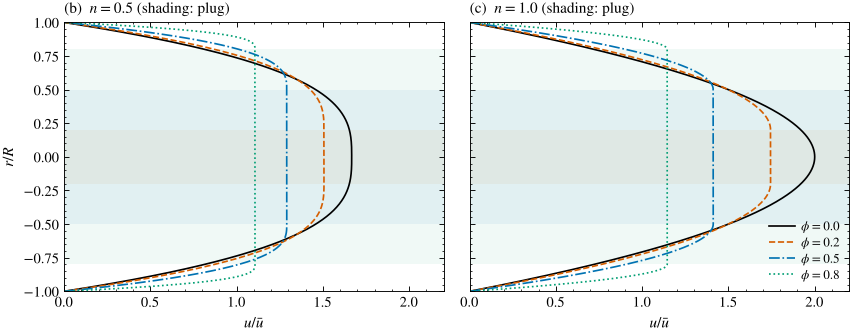

Fig. 8(b,c): all profile values agree with data/figure_data/fig08_pipe_profiles.csv (rtol 1e-8).


In [4]:
fd8 = pd.read_csv(ROOT / "data" / "figure_data" / "fig08_pipe_profiles.csv", comment="#")
def stored8(panel, series):
    s = fd8[(fd8.panel == panel) & (fd8.series == series)].sort_values("index")
    return s.x.to_numpy(), s.y.to_numpy()

r = np.linspace(-1, 1, 601)
phis = [0.0, 0.2, 0.5, 0.8]
cols = [C["black"], C["red"], C["blue"], C["green"]]
lss = ["-", "--", "-.", ":"]
fig, axes = plt.subplots(1, 2, figsize=(8.0, 3.3), sharey=True)
for ax, n, panel in zip(axes, [0.5, 1.0], ["(b)", "(c)"]):
    for phi, col, ls in zip(phis, cols, lss):
        u = velocity(r, 1.0, phi, 1.0, n)
        ubar = flow_rate_eq19(1.0, phi, 1.0, n) / np.pi
        ax.plot(u / ubar, r, color=col, ls=ls, label=rf"$\phi={phi}$")
        ax.axhspan(-phi, phi, color=col, alpha=0.06, lw=0)                 # plug |r| < r_p
        xs, ys = stored8(panel, f"$\\phi={phi}$")
        assert np.allclose(xs, u / ubar, rtol=1e-8, atol=1e-12) and np.allclose(ys, r, rtol=1e-8, atol=1e-12)
    ax.set_xlabel(r"$u/\bar u$")
    ax.set_xlim(0, 2.2); ax.set_ylim(-1, 1)
    ax.set_title(f"{panel}  $n={n}$ (shading: plug)", loc="left", fontsize=10)
axes[0].set_ylabel(r"$r/R$")
axes[1].legend(loc="lower right", fontsize=8.5)
fig.tight_layout()
plt.show()
print("Fig. 8(b,c): all profile values agree with data/figure_data/fig08_pipe_profiles.csv (rtol 1e-8).")

The Newtonian profile ($n=1$, $\phi=0$) is the familiar parabola with $u_{\max}=2\bar u$. Shear thinning ($n=0.5$) blunts it, and a yield stress flattens the core: for $\phi=0.8$ the plug fills 80 % of the radius and moves at only about 1.1 times the mean velocity. Fig. 8(a) of the review is a schematic and has no plotted data.

## 4. The flow rate

### 4.1 Eq. (19) against numerical integration, and Eq. (19) against Eq. (23)

We compute $Q$ three ways: Eq. (19), Eq. (23), and direct quadrature of $Q=2\pi\int_0^R u\,r\,\mathrm{d}r$ with $u$ from Eq. (18). We also compare with `pipe_q` from `scripts/verify_equations.py`, the review's own implementation of Eq. (23).

In [5]:
worst19_23 = worst_quad = worst_script = 0.0
K, R = 0.8, 0.7                        # arbitrary values, so that no factor of K or R hides an error
for n in [0.35, 0.5, 0.7, 1.0, 1.4]:
    for phi in [0.0, 0.1, 0.5, 0.9, 0.99]:
        tw = 2.0
        ty = phi * tw
        q19 = flow_rate_eq19(tw, ty, K, n, R)
        q23 = flow_rate_eq23(tw - ty, ty, K, n, R)
        q_quad = 2 * np.pi * quad(lambda s: velocity(s, tw, ty, K, n, R) * s, 0, R, points=[phi * R], epsabs=0, epsrel=1e-12)[0]
        worst19_23 = max(worst19_23, abs(q19 / q23 - 1))
        worst_quad = max(worst_quad, abs(q19 / q_quad - 1))
        worst_script = max(worst_script, abs(q19 / pipe_q(tw, ty, K, n, R) - 1))
print(f"Eq.(19) vs Eq.(23):               {worst19_23:.1e}")
print(f"Eq.(19) vs quadrature of u(r):    {worst_quad:.1e}")
print(f"Eq.(19) vs scripts/verify_equations.pipe_q: {worst_script:.1e}")
assert max(worst19_23, worst_quad, worst_script) < 1e-9

Eq.(19) vs Eq.(23):               2.0e-15
Eq.(19) vs quadrature of u(r):    8.3e-15
Eq.(19) vs scripts/verify_equations.pipe_q: 2.0e-15


### 4.2 Classical limits

In [6]:
mu, R, G = 2.0, 0.4, 3.0
tw = G * R / 2
# Newtonian: Poiseuille
assert np.isclose(flow_rate_eq19(tw, 0.0, mu, 1.0, R), np.pi * R**4 * G / (8 * mu), rtol=1e-12)
# power law (phi = 0)
for n in [0.4, 0.7, 1.3]:
    assert np.isclose(flow_rate_eq19(tw, 0.0, mu, n, R), np.pi * R**3 * n / (3 * n + 1) * (tw / mu) ** (1 / n), rtol=1e-12)
# Bingham: Buckingham-Reiner
for phi in [0.1, 0.4, 0.8]:
    br = np.pi * R**3 * tw / (4 * mu) * (1 - 4 * phi / 3 + phi**4 / 3)
    assert np.isclose(flow_rate_eq19(tw, phi * tw, mu, 1.0, R), br, rtol=1e-12)
print("Eq. (19) reduces to Poiseuille, the power-law result and the Buckingham-Reiner equation.")

Eq. (19) reduces to Poiseuille, the power-law result and the Buckingham-Reiner equation.


### 4.3 Energy check: pressure work equals dissipation

Supplementary Note S9 E gives an independent check, Eq. (S24): per unit length, the power supplied by the pressure gradient equals the power dissipated in the sheared annulus,
$GQ = 2\pi\int_0^R\left(\sigma_y\dot\gamma+K\dot\gamma^{n+1}\right)r\,\mathrm{d}r$. The plug moves but dissipates nothing. The review notes that this identity "detects a missing factor of two in the invariant, a sign error or an inconsistent slip traction more reliably than a velocity plot".

In [7]:
worst = 0.0
K, R = 0.8, 0.7
for n in [0.35, 0.7, 1.0, 1.4]:
    for phi in [0.0, 0.3, 0.9]:
        tw = 2.0; ty = phi * tw; G = 2 * tw / R
        gd = lambda s: shear_rate(s, tw, ty, K, n, R)
        dissipation = 2 * np.pi * quad(lambda s: (ty * gd(s) + K * gd(s) ** (n + 1)) * s, phi * R, R, epsabs=0, epsrel=1e-12, limit=200)[0]
        worst = max(worst, abs(G * flow_rate_eq19(tw, ty, K, n, R) / dissipation - 1))
print(f"pressure work / dissipation - 1: largest = {worst:.1e}")
assert worst < 1e-9

pressure work / dissipation - 1: largest = 4.9e-15


### 4.4 Dimensionless flow rate and plug velocity — Fig. S6

Dividing Eq. (19) by $\pi R^3(\sigma_w/K)^{1/n}$ leaves a function of $\phi$ and $n$ only, $Q^*(\phi,n)$. The plug velocity divided by the mean velocity is $u_p/\bar u=\dfrac{n}{n+1}(1-\phi)^{(n+1)/n}/Q^*$. We reproduce both panels of Fig. S6 and check them against `data/figure_data/figS6_flow_rate.csv`.

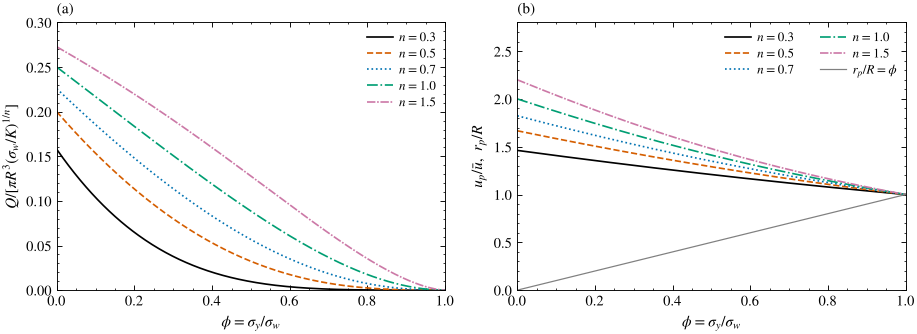

Fig. S6(a,b): all plotted values agree with data/figure_data/figS6_flow_rate.csv (rtol 1e-8).


In [8]:
fdS6 = pd.read_csv(ROOT / "data" / "figure_data" / "figS6_flow_rate.csv", comment="#")
def storedS6(panel, series):
    s = fdS6[(fdS6.panel == panel) & (fdS6.series == series)].sort_values("index")
    return s.x.to_numpy(), s.y.to_numpy()

Qstar = lambda phi, n: np.array([flow_rate_eq19(1.0, p, 1.0, n) / np.pi for p in np.atleast_1d(phi)])
plug_over_mean = lambda phi, n: (n / (n + 1)) * (1 - phi) ** ((n + 1) / n) / Qstar(phi, n)

phi = np.linspace(0, 0.999, 400)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8.6, 3.3))
for n, col, ls in zip([0.3, 0.5, 0.7, 1.0, 1.5], [C["black"], C["red"], C["blue"], C["green"], C["purple"]],
                      ["-", "--", ":", "-.", (0, (5, 1, 1, 1))]):
    q, up = Qstar(phi, n), plug_over_mean(phi, n)
    ax1.plot(phi, q, color=col, ls=ls, label=f"$n={n}$")
    ax2.plot(phi, up, color=col, ls=ls, label=f"$n={n}$")
    for panel, y in [("(a)", q), ("(b)", up)]:
        xs, ys = storedS6(panel, f"$n={n}$")
        assert np.allclose(xs, phi, rtol=1e-8) and np.allclose(ys, y, rtol=1e-8, atol=1e-14)
ax2.plot(phi, phi, color=C["grey"], lw=0.8, label=r"$r_p/R=\phi$")
ax1.set(xlabel=r"$\phi=\sigma_y/\sigma_w$", ylabel=r"$Q/[\pi R^3(\sigma_w/K)^{1/n}]$", xlim=(0, 1), ylim=(0, 0.3))
ax2.set(xlabel=r"$\phi=\sigma_y/\sigma_w$", ylabel=r"$u_p/\bar u,\; r_p/R$", xlim=(0, 1), ylim=(0, 2.8))
ax1.legend(fontsize=8.5); ax2.legend(fontsize=8.5, ncol=2)
ax1.set_title("(a)", loc="left", fontsize=10); ax2.set_title("(b)", loc="left", fontsize=10)
fig.tight_layout()
plt.show()
print("Fig. S6(a,b): all plotted values agree with data/figure_data/figS6_flow_rate.csv (rtol 1e-8).")

At $\phi=0$ the plug velocity is the centreline velocity of the power-law profile, $u_p/\bar u=(3n+1)/(n+1)$ (2 for a Newtonian fluid). As $\phi\to1$ the plug fills the pipe and $u_p/\bar u\to1$, while $Q^*\to0$.

## 5. The threshold for flow and the near-onset exponent

### 5.1 Why Eq. (23) is needed near onset

Close to onset, $1-\phi$ in Eq. (19) is computed from $\phi=\sigma_y/\sigma_w$ and loses digits; Eq. (23) uses $\delta$ directly. The next cell evaluates both at $\sigma_w=\sigma_y(1+\varepsilon)$.

In [9]:
ty, K, n = 1.0, 1.0, 0.5
for eps in [1e-4, 1e-8, 1e-12]:
    q19 = flow_rate_eq19(ty * (1 + eps), ty, K, n)
    q23 = flow_rate_eq23(ty * eps, ty, K, n)
    print(f"delta/sigma_y = {eps:.0e}:  Eq.(19)/Eq.(23) - 1 = {q19 / q23 - 1:+.1e}")

delta/sigma_y = 1e-04:  Eq.(19)/Eq.(23) - 1 = +5.0e-13
delta/sigma_y = 1e-08:  Eq.(19)/Eq.(23) - 1 = -2.2e-08
delta/sigma_y = 1e-12:  Eq.(19)/Eq.(23) - 1 = +2.7e-04


At $\delta/\sigma_y=10^{-12}$ Eq. (19) is wrong in the fourth digit — harmless for a pressure-drop calculation, fatal for a logarithmic slope (Supplementary Note S11 A).

### 5.2 Exponent crossover — Fig. 9(a)

We compute $Q$ from Eq. (23) at $n=0.5$ for $(G-G_c)/G_c$ from $10^{-5}$ to $10^4$ (note $(G-G_c)/G_c=\delta/\sigma_y$), take the logarithmic derivative numerically exactly as the figure script does, and compare with `data/figure_data/fig09_transport_exponents.csv`.

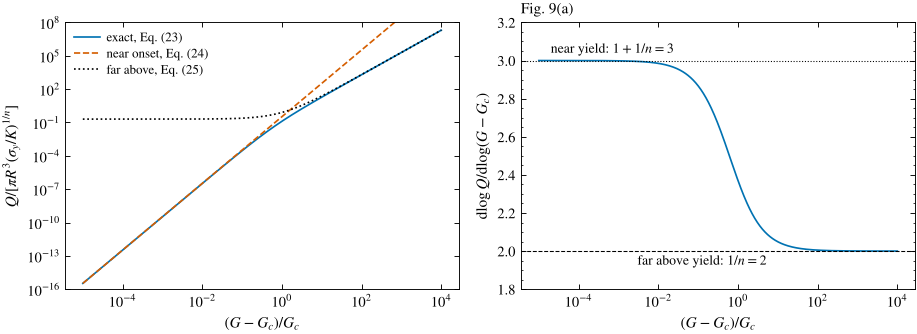

Fig. 9(a): slope curve and both limits agree with data/figure_data/fig09_transport_exponents.csv (rtol 1e-8).


In [10]:
fd9 = pd.read_csv(ROOT / "data" / "figure_data" / "fig09_transport_exponents.csv", comment="#")
n = 0.5
e = np.logspace(-5, 4, 700)                                  # (G - Gc)/Gc = delta/sigma_y with sigma_y = 1
q = np.array([flow_rate_eq23(x, 1.0, 1.0, n) for x in e])
slope = np.gradient(np.log(q), np.log(e))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8.6, 3.3))
ax1.loglog(e, q / np.pi, color=C["blue"], label="exact, Eq. (23)")
ax1.loglog(e, n / (n + 1) * e ** (1 + 1 / n), color=C["red"], ls="--", label="near onset, Eq. (24)")
ax1.loglog(e, n / (3 * n + 1) * (1 + e) ** (1 / n), color=C["black"], ls=":", label="far above, Eq. (25)")
ax1.set(xlabel=r"$(G-G_c)/G_c$", ylabel=r"$Q/[\pi R^3(\sigma_y/K)^{1/n}]$", ylim=(1e-16, 1e8))
ax1.legend(fontsize=8.5)
ax2.semilogx(e, slope, color=C["blue"], label="exact pipe solution")
ax2.axhline(1 + 1 / n, color="k", ls=":", lw=0.7); ax2.axhline(1 / n, color="k", ls="--", lw=0.7)
ax2.text(2e-5, 3.02, r"near yield: $1+1/n=3$", fontsize=9, va="bottom")
ax2.text(3e-3, 1.98, r"far above yield: $1/n=2$", fontsize=9, va="top")
ax2.set(xlabel=r"$(G-G_c)/G_c$", ylabel=r"$\mathrm{d}\log Q/\mathrm{d}\log(G-G_c)$", ylim=(1.8, 3.2))
ax2.set_title("Fig. 9(a)", loc="left", fontsize=10)
fig.tight_layout()
plt.show()

s = fd9[(fd9.panel == "(a)") & (fd9.series == "exact pipe solution")].sort_values("index")
assert np.allclose(s.x.to_numpy(), e, rtol=1e-8) and np.allclose(s.y.to_numpy(), slope, rtol=1e-8)
h = fd9[(fd9.panel == "(a)") & (fd9.kind == "hline")].set_index("series").y
assert np.isclose(h["near-yield limit 1+1/n"], 1 + 1 / n) and np.isclose(h["far-from-yield limit 1/n"], 1 / n)
print("Fig. 9(a): slope curve and both limits agree with data/figure_data/fig09_transport_exponents.csv (rtol 1e-8).")

The crossover is slow: the slope is still about 2.4 when $G=2G_c$, falls to 2.05 only when $G\approx11\,G_c$, and is within 0.5 % of $1/n$ only when $G$ exceeds $G_c$ by about 1.7 decades ($G\approx50\,G_c$). A single power of the pressure fitted over a typical experimental range — which is what Herschel and Bulkley did in 1926 (Sec. II) — cannot return $1/n$. Note also the order of limits stressed in Sec. VII C: taking $\sigma_y\to0$ before approaching onset removes the sheared-annulus mechanism, so the near-onset exponent of a yield-stress fluid does not tend to the power-law exponent $1/n$.

## 6. Plane-channel flow

We check the channel flow rate, Eq. (20), and its excess-stress form (S17), against quadrature of the channel velocity profile. The profile follows from the same integration as Eq. (18) with $\sigma(y)=\sigma_w|y|/H$:
$u(y)=\dfrac{n}{n+1}\dfrac{H}{\sigma_w}K^{-1/n}\left[(\sigma_w-\sigma_y)^{\frac{n+1}{n}}-\left(\sigma_w\frac{|y|}{H}-\sigma_y\right)_+^{\frac{n+1}{n}}\right]$ (this formula is not printed in the review but is the one coded in `scripts/verify_equations.py`).

In [11]:
def channel_velocity(y, tw, ty, K, n, H=1.0):
    excess = np.clip(tw * np.abs(np.asarray(y, float)) / H - ty, 0.0, None)
    return n / (n + 1) * (H / tw) * K ** (-1 / n) * ((tw - ty) ** ((n + 1) / n) - excess ** ((n + 1) / n))

def channel_q(tw, ty, K, n, H=1.0):
    """Flow rate per unit width, Eq. (20)."""
    if tw <= ty:
        return 0.0
    phi = ty / tw
    return 2 * H**2 * n * (tw / K) ** (1 / n) * (1 - phi) ** ((n + 1) / n) * ((1 - phi) / (2 * n + 1) + phi / (n + 1))

def channel_q_S17(delta, ty, K, n, H=1.0):
    """Eq. (S17)."""
    tw = ty + delta
    return 2 * H**2 / (K ** (1 / n) * tw**2) * (delta ** (2 + 1 / n) / (2 + 1 / n) + ty * delta ** (1 + 1 / n) / (1 + 1 / n))

worst = 0.0
tw, K, H = 2.0, 0.8, 0.6
for n in [0.4, 0.7, 1.0, 1.4]:
    for phi in [0.0, 0.2, 0.6, 0.9]:
        ty = phi * tw
        q_num = 2 * quad(lambda y: channel_velocity(y, tw, ty, K, n, H), 0, H, points=[phi * H], epsrel=1e-12)[0]
        worst = max(worst, abs(channel_q(tw, ty, K, n, H) / q_num - 1), abs(channel_q_S17(tw - ty, ty, K, n, H) / q_num - 1))
# Newtonian slot: q = 2 G H^3 / (3 mu)
assert np.isclose(channel_q(2.0 * H, 0.0, 0.8, 1.0, H), 2 * 2.0 * H**3 / (3 * 0.8))
print(f"channel q (Eq. 20 and Eq. S17) vs quadrature of u(y): largest relative difference = {worst:.1e}")
assert worst < 1e-9

# near-onset exponent of the channel (Table SIV): q ~ delta^(1 + 1/n)
for n in [0.4, 0.7, 1.0]:
    d1, d2 = 1e-6, 2e-6
    print(f"n = {n}: channel near-onset slope = {np.log(channel_q_S17(d2, 1, 1, n) / channel_q_S17(d1, 1, 1, n)) / np.log(2):.4f}"
          f"   (1 + 1/n = {1 + 1/n:.4f})")

channel q (Eq. 20 and Eq. S17) vs quadrature of u(y): largest relative difference = 4.0e-11
n = 0.4: channel near-onset slope = 3.5000   (1 + 1/n = 3.5000)
n = 0.7: channel near-onset slope = 2.4286   (1 + 1/n = 2.4286)
n = 1.0: channel near-onset slope = 2.0000   (1 + 1/n = 2.0000)


The channel behaves like the pipe: the plug occupies $|y|<\phi H$, onset requires $G>\sigma_y/H$ (half the pipe value for $H=R$, because the force balance on a slab gives $\sigma=G|y|$ rather than $Gr/2$), and the near-onset exponent is again $1+1/n$ because two thin wall layers open.

## 7. Convex duality: the plug as the flat part of a conjugate

Sec. VII A notes that Eq. (18) can be read as a statement of convex duality. The HB law derives from the convex dissipation potential (Sec. IV A)

$$
\Psi(\dot\gamma)=\sigma_y\dot\gamma+\frac{K\dot\gamma^{\,n+1}}{n+1},\qquad\dot\gamma\ge0 ,
$$

in the sense that the stress is its subgradient: $\sigma=\Psi'(\dot\gamma)=\sigma_y+K\dot\gamma^n$ for $\dot\gamma>0$, while at $\dot\gamma=0$ any $\sigma\le\sigma_y$ is admissible. (Do not confuse $\Psi$ with the dissipation rate $\sigma\dot\gamma=\sigma_y\dot\gamma+K\dot\gamma^{n+1}$, Eq. (7).) Its Legendre–Fenchel conjugate is

$$
\Psi^*(\sigma)=\sup_{\dot\gamma\ge0}\left[\sigma\dot\gamma-\Psi(\dot\gamma)\right].
$$

For $\sigma\le\sigma_y$ the bracket is never positive, so $\Psi^*=0$. For $\sigma>\sigma_y$ the supremum is reached where $\sigma=\Psi'(\dot\gamma)$, i.e. at the HB shear rate $\dot\gamma(\sigma)=[(\sigma-\sigma_y)/K]^{1/n}$, giving

$$
\Psi^*(\sigma)=\frac{n}{n+1}K^{-1/n}(\sigma-\sigma_y)_+^{\frac{n+1}{n}},\qquad \frac{\mathrm{d}\Psi^*}{\mathrm{d}\sigma}=\dot\gamma(\sigma).
$$

The derivative of the conjugate is the inverse flow curve. Since $u(r)=\int_r^R\dot\gamma(\sigma_w r'/R)\,\mathrm{d}r'$, the substitution $s=\sigma_w r'/R$ gives the review's statement

$$
u(r)=\frac{R}{\sigma_w}\left[\Psi^*(\sigma_w)-\Psi^*\!\left(\sigma_w\frac{r}{R}\right)\right].
$$

Because $\Psi^*$ is flat (zero) for $\sigma\le\sigma_y$, $u$ is constant for $r\le r_p$: the plug comes out of the conjugate, not from a separate assumption. Below we compute $\Psi^*$ **numerically**, by maximizing $\sigma\dot\gamma-\Psi(\dot\gamma)$ for each $\sigma$ without using the closed form, and check both statements.

max |Psi*_numeric - Psi*_closed| = 1.3e-15
max |argmax - HB shear rate|     = 7.6e-08


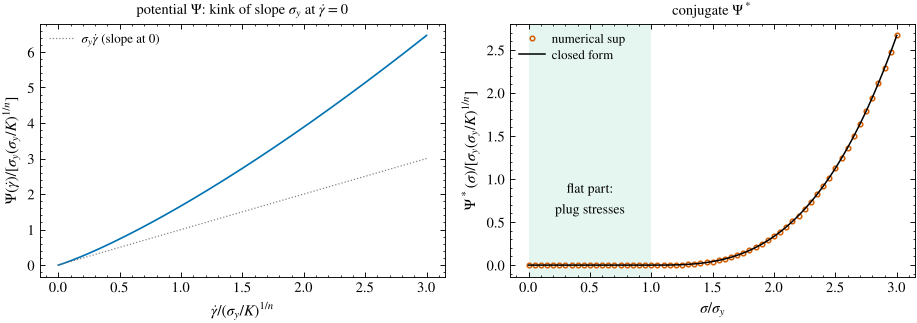

In [12]:
ty, K, n = 1.0, 1.0, 0.5                      # sigma_y, K, n (dimensionless)
Psi = lambda g: ty * g + K * g ** (n + 1) / (n + 1)

def Psi_star_numeric(sigma):
    """Legendre-Fenchel conjugate by direct numerical maximization over gdot >= 0."""
    g_hi = 10.0 * (max(sigma, ty) / K) ** (1 / n) + 1.0          # safely beyond the maximizer
    res = minimize_scalar(lambda g: -(sigma * g - Psi(g)), bounds=(0.0, g_hi), method="bounded",
                          options={"xatol": 1e-12})
    return max(-res.fun, 0.0), res.x                            # value of the sup, and the maximizer

Psi_star_closed = lambda s: n / (n + 1) * K ** (-1 / n) * np.clip(s - ty, 0, None) ** ((n + 1) / n)

sig = np.linspace(0, 3, 61)
num = np.array([Psi_star_numeric(s) for s in sig])
print(f"max |Psi*_numeric - Psi*_closed| = {np.max(np.abs(num[:, 0] - Psi_star_closed(sig))):.1e}")
print(f"max |argmax - HB shear rate|     = {np.max(np.abs(num[:, 1] - ((np.clip(sig - ty, 0, None) / K) ** (1 / n)))):.1e}")
assert np.allclose(num[:, 0], Psi_star_closed(sig), atol=1e-9)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8.6, 3.2))
g = np.linspace(0, 3, 200)
ax1.plot(g, Psi(g), color=C["blue"])
ax1.plot(g, ty * g, color=C["grey"], ls=":", lw=0.8, label=r"$\sigma_y\dot\gamma$ (slope at 0)")
ax1.set(xlabel=r"$\dot\gamma/(\sigma_y/K)^{1/n}$", ylabel=r"$\Psi(\dot\gamma)/[\sigma_y(\sigma_y/K)^{1/n}]$",
        title=r"potential $\Psi$: kink of slope $\sigma_y$ at $\dot\gamma=0$")
ax1.legend(fontsize=8.5)
ax2.plot(sig, num[:, 0], "o", ms=3, mfc="none", color=C["red"], label="numerical sup")
ax2.plot(sig, Psi_star_closed(sig), color=C["black"], lw=1, label="closed form")
ax2.axvspan(0, ty, color=C["green"], alpha=0.1, lw=0)
ax2.text(0.5, 0.6, "flat part:\nplug stresses", ha="center", fontsize=9)
ax2.set(xlabel=r"$\sigma/\sigma_y$", ylabel=r"$\Psi^*(\sigma)/[\sigma_y(\sigma_y/K)^{1/n}]$", title=r"conjugate $\Psi^*$")
ax2.legend(fontsize=8.5, loc="upper left")
for a in (ax1, ax2): a.title.set_fontsize(9.5)
fig.tight_layout()
plt.show()

Now the velocity profile. We build $u(r)$ from the numerical conjugate and compare it with Eq. (18) for $\phi=0.4$.

max |u_dual - u_Eq18| / u_plug = 6.5e-16
plug radius r_p/R = 0.40; spread of u inside the plug = 0.0e+00 (flat)


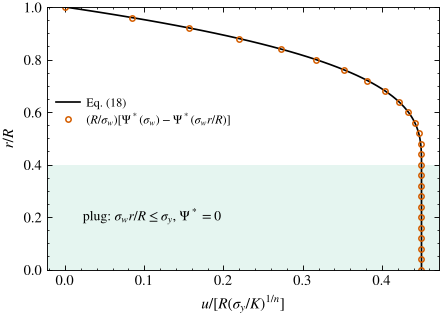

In [13]:
tw, R = 2.5, 1.0                                  # phi = sigma_y / sigma_w = 0.4
rr = np.linspace(0, R, 101)
Ps_w = Psi_star_numeric(tw)[0]
u_dual = np.array([R / tw * (Ps_w - Psi_star_numeric(tw * x / R)[0]) for x in rr])
u_eq18 = velocity(rr, tw, ty, K, n, R)
print(f"max |u_dual - u_Eq18| / u_plug = {np.max(np.abs(u_dual - u_eq18)) / u_eq18.max():.1e}")
assert np.allclose(u_dual, u_eq18, rtol=0, atol=1e-8 * u_eq18.max())

rp = plug_radius(tw, ty, R)
in_plug = rr <= rp
print(f"plug radius r_p/R = {rp:.2f}; spread of u inside the plug = {np.ptp(u_dual[in_plug]):.1e} (flat)")

fig, ax = plt.subplots(figsize=(4.6, 3.1))
ax.plot(u_eq18, rr, color=C["black"], label="Eq. (18)")
ax.plot(u_dual[::4], rr[::4], "o", ms=3.5, mfc="none", color=C["red"], label=r"$(R/\sigma_w)[\Psi^*(\sigma_w)-\Psi^*(\sigma_w r/R)]$")
ax.axhspan(0, rp, color=C["green"], alpha=0.1, lw=0)
ax.text(0.05 * u_eq18.max(), rp / 2, r"plug: $\sigma_w r/R\leq\sigma_y$, $\Psi^*=0$", fontsize=9, va="center")
ax.set(xlabel=r"$u/[R(\sigma_y/K)^{1/n}]$", ylabel=r"$r/R$", ylim=(0, 1))
ax.legend(fontsize=8, loc="center left", bbox_to_anchor=(0.0, 0.6))
plt.show()

The duality reading is more than a curiosity. It generalizes to any convex dissipation potential: the review cites Wang, Sydyk and Omirbekov (2026), who used this form to obtain profiles and flow rates for the HB–Papanastasiou law, and the variational treatments of Sochi (2014, 2015).

## 8. Summary of the formulas, in code

`scripts/hb_prediction.py` implements Eq. (23) in SI units (`pipe_flux`) and inverts it for the pressure gradient (`pressure_gradient`, bracketing plus Brent's method). We confirm that it agrees with our Eq. (19).

In [14]:
worst = 0.0
for n in [0.35, 0.7, 1.0, 1.4]:
    for ratio in [1.001, 2.0, 10.0]:
        ty, Kc, Rp = 6.0, 0.8, 0.01            # Pa, Pa s^n, m
        tw = ratio * ty
        worst = max(worst, abs(float(hb_prediction.pipe_flux(tw, Rp, ty, Kc, n)) / flow_rate_eq19(tw, ty, Kc, n, Rp) - 1))
print(f"hb_prediction.pipe_flux vs Eq. (19): largest relative difference = {worst:.1e}")
assert worst < 1e-9

hb_prediction.pipe_flux vs Eq. (19): largest relative difference = 1.4e-13


## 9. Worked engineering example: pumping a drilling fluid (beyond the article)

**Problem.** A water-based drilling fluid is to be circulated at $Q=400$ L/min through a drill pipe of inner diameter $D=0.10$ m. What pressure gradient is needed, how large is the plug, and how does the required pressure gradient depend on the flow rate?

**Fluid.** We take the HB parameters of the water-based drilling fluid of Skadsem and Saasen (2019), as listed in the review's parameter atlas (`data/hb_parameter_atlas.csv`, plotted in Fig. 3): $\sigma_y=4.29$ Pa, $K=0.70$ Pa s$^{0.52}$, $n=0.52$. The density is not part of the atlas; we **assume** $\rho=1200$ kg/m$^3$, used only to check that the flow is laminar.

**Assumptions.** Steady, fully developed, isothermal, laminar flow; no wall slip; a non-rotating, concentric pipe; the fluid is in the state in which it was characterized (no thixotropic evolution). Table XIII of the review lists what else must be measured for a reliable pressure-loss prediction: a calibration window covering the operating wall shear rates, a slip test on the pipe material, and $\dot\gamma_c$ for thixotropic fluids.

In [15]:
atlas = pd.read_csv(ROOT / "data" / "hb_parameter_atlas.csv")
row = atlas[atlas.material == "Water-based drilling fluid"].iloc[0]
ty, K, n = float(row.sigma_y_Pa), float(row.K_Pa_s_n), float(row.n)
print(f"{row.material} ({row.source_key}, {row.source_location}): sigma_y = {ty} Pa, K = {K} Pa s^n, n = {n}")

rho = 1200.0                 # kg/m^3, ASSUMED (not part of the atlas entry)
D = 0.10                     # m, pipe inner diameter
R = D / 2
Q = 400 / 1000 / 60          # 400 L/min in m^3/s

Water-based drilling fluid (SkadsemSaasen2019, Sec. 4.1): sigma_y = 4.29 Pa, K = 0.7 Pa s^n, n = 0.52


In [16]:
# Step 1: required pressure gradient (exact laminar HB model, scripts/hb_prediction.py)
G = hb_prediction.pressure_gradient(Q, R, ty, K, n)       # Pa/m
tw = G * R / 2                                            # wall shear stress from the momentum balance
phi = ty / tw
U = Q / (np.pi * R**2)                                    # mean velocity
Gc = 2 * ty / R                                           # Eq. (22): gradient needed just to start flow

# Step 2: check that the solution reproduces the imposed flow rate
assert np.isclose(flow_rate_eq19(tw, ty, K, n, R), Q, rtol=1e-9)

# Step 3: laminar check with the Metzner-Reed Reynolds number, Eq. (9), which equals 8 rho U^2 / sigma_w in laminar flow
Re_MR = 8 * rho * U**2 / tw

print(f"mean velocity          U       = {U:.3f} m/s")
print(f"pressure gradient      G       = {G:.0f} Pa/m  = {G * 1000 / 1e5:.2f} bar per 1000 m")
print(f"wall shear stress      sigma_w = {tw:.2f} Pa   (phi = sigma_y/sigma_w = {phi:.3f})")
print(f"plug radius            r_p     = {1000 * phi * R:.1f} mm  of R = {1000 * R:.0f} mm")
print(f"threshold gradient     G_c     = {Gc:.0f} Pa/m  ({100 * Gc / G:.0f} % of the gradient needed)")
print(f"Metzner-Reed Reynolds  Re_MR   = {Re_MR:.0f}  -> laminar")

mean velocity          U       = 0.849 m/s
pressure gradient      G       = 490 Pa/m  = 4.90 bar per 1000 m
wall shear stress      sigma_w = 12.25 Pa   (phi = sigma_y/sigma_w = 0.350)
plug radius            r_p     = 17.5 mm  of R = 50 mm
threshold gradient     G_c     = 172 Pa/m  (35 % of the gradient needed)
Metzner-Reed Reynolds  Re_MR   = 565  -> laminar


About 0.49 kPa per metre — roughly 4.9 bar per kilometre of pipe — is needed, and 35 % of it is the yield-stress threshold $G_c=2\sigma_y/R$ that must be overcome before anything moves. The plug occupies the central 35 % of the radius. The Reynolds number lies well below the illustrative transition band of Supplementary Fig. S7 ($\mathrm{Re_{MR}}\approx2100$–3000), so the laminar solution applies; turbulent flow and the friction factor are the subject of notebook 08.

**The "pump curve".** Plotting $G$ against $Q$ shows the finite intercept at $Q\to0$ and the slow, sub-linear rise with flow rate; the dashed line is the power-law fluid with the same $K$ and $n$ but no yield stress.

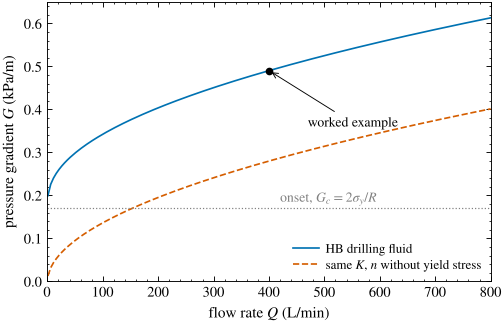

In [17]:
Q_lpm = np.linspace(1, 800, 160)
G_hb = np.array([hb_prediction.pressure_gradient(q / 60000, R, ty, K, n) for q in Q_lpm])
G_pl = np.array([hb_prediction.pressure_gradient(q / 60000, R, 0.0, K, n) for q in Q_lpm])

fig, ax = plt.subplots(figsize=(5.2, 3.3))
ax.plot(Q_lpm, G_hb / 1000, color=C["blue"], label="HB drilling fluid")
ax.plot(Q_lpm, G_pl / 1000, color=C["red"], ls="--", label=r"same $K$, $n$ without yield stress")
ax.axhline(Gc / 1000, color=C["grey"], ls=":", lw=0.8)
ax.text(420, Gc / 1000 + 0.012, r"onset, $G_c=2\sigma_y/R$", fontsize=9, color=C["grey"])
ax.plot([400], [G / 1000], "o", color=C["black"], ms=4)
ax.annotate("worked example", (400, G / 1000), xytext=(470, 0.36), fontsize=9, arrowprops=dict(arrowstyle="->", lw=0.6))
ax.set(xlabel=r"flow rate $Q$ (L/min)", ylabel=r"pressure gradient $G$ (kPa/m)", xlim=(0, 800), ylim=(0, 0.65))
ax.legend(loc="lower right", fontsize=8.5)
plt.show()

## 10. Try it yourself

**Exercise 1 — how much does the yield stress matter?** For the drilling fluid of Sec. 9, change $\sigma_y$ by $\pm20$ % and compute the relative change of the required pressure gradient at 50 L/min and at 600 L/min. Which operating point determines $\sigma_y$ better? (Compare with Secs. VI F and IX E of the review.)

*Hint:* call `hb_prediction.pressure_gradient(Q, R, 1.2 * ty, K, n)`.

<details><summary>Solution</summary>

```python
for q_lpm in [50, 600]:
    q = q_lpm / 60000
    g0 = hb_prediction.pressure_gradient(q, R, ty, K, n)
    for f in [0.8, 1.2]:
        print(q_lpm, f, f"{100 * (hb_prediction.pressure_gradient(q, R, f * ty, K, n) / g0 - 1):+.1f} %")
# About +/-13 % at 50 L/min but only about +/-7.5 % at 600 L/min: the high-flow pressure loss
# constrains sigma_y weakly, and a low-flow (restart-like) prediction depends strongly on it.
```
</details>

**Exercise 2 — the near-onset asymptote.** For $n=1$ (Bingham), check numerically that Eq. (24) gives $Q\sim\pi R^3\delta^2/(2\mu_p\sigma_y)$, and find the value of $\delta/\sigma_y$ at which the asymptote is in error by 10 %.

*Hint:* use `flow_rate_eq23` and `brentq` on the ratio minus 1.1 (or 0.9).

<details><summary>Solution</summary>

```python
ty, mu = 1.0, 1.0
asym = lambda d: np.pi * d**2 / (2 * mu * ty)
ratio = lambda d: asym(d) / flow_rate_eq23(d, ty, mu, 1.0)
print([ratio(d) for d in [1e-4, 1e-2, 1e-1]])
print("10 % error at delta/sigma_y =", brentq(lambda d: ratio(d) - 1.1, 1e-4, 1.0))   # about 0.06
```
</details>

**Exercise 3 — slot versus pipe.** A paste is pushed through a slot of half-width $H=5$ mm and through a pipe of radius $R=5$ mm. Using Eq. (22), which needs the larger pressure gradient to start flowing? With $\sigma_y=50$ Pa, $K=10$ Pa s$^{0.4}$, $n=0.4$ and $G=1.5\times$ the pipe threshold, compare the mean velocities (pipe: $Q/(\pi R^2)$; slot: $q/(2H)$).

<details><summary>Solution</summary>

```python
ty, K, n, H = 50.0, 10.0, 0.4, 0.005
G = 1.5 * 2 * ty / H                       # 1.5 times the pipe threshold; three times the slot threshold
U_pipe = flow_rate_eq19(G * H / 2, ty, K, n, H) / (np.pi * H**2)
U_slot = channel_q(G * H, ty, K, n, H) / (2 * H)
print(2 * ty / H, ty / H, U_pipe, U_slot)  # the pipe needs twice the gradient to start; at this G the slot flows about 60 times faster
```
</details>

## Key points

* In fully developed pipe flow the shear stress is $\sigma=Gr/2$ for **any** fluid; the HB fluid has a rigid plug of radius $r_p=R\sigma_y/\sigma_w$.
* Eqs. (18) and (19) give the exact laminar profile and flow rate; they reduce to Poiseuille, power-law and Buckingham–Reiner results and satisfy the pressure-work/dissipation identity (S24).
* Flow starts only above $G_c=2\sigma_y/R$ (pipe) or $\sigma_y/H$ (channel), independently of $K$ and $n$.
* Near onset $Q\propto(G-G_c)^{1+1/n}$; far above it $Q\propto G^{1/n}$; the crossover spans several decades, so an observed pressure–flow exponent is not the material's $1/n$.
* Eq. (18) is $u(r)=(R/\sigma_w)[\Psi^*(\sigma_w)-\Psi^*(\sigma_w r/R)]$; the plug is where the conjugate of the dissipation potential is flat.
* For design, `hb_prediction.pressure_gradient` inverts Eq. (19); always check the laminar assumption with $\mathrm{Re_{MR}}=8\rho U^2/\sigma_w$ and the assumptions behind the parameters (slip, window, thixotropy).

## References

The review and its repository:
* Y. Wang (2026). A century of the Herschel–Bulkley model (1926–2026): Widespread use, community achievements, predictive capability, and engineering implications. Manuscript submitted to the *Journal of Rheology*; code and data: https://github.com/ktwyw/hb-centenary-review

* Buckingham, E. (1921). On plastic flow through capillary tubes. *Proceedings of the American Society for Testing Materials* **21**, 1154–1156.
* Herschel, W. H., and Bulkley, R. (1926). Konsistenzmessungen von Gummi-Benzollösungen. *Kolloid-Zeitschrift* **39**, 291–300. https://doi.org/10.1007/bf01432034
* Metzner, A. B., and Reed, J. C. (1955). Flow of non-Newtonian fluids — correlation of the laminar, transition, and turbulent-flow regions. *AIChE Journal* **1**, 434–440. https://doi.org/10.1002/aic.690010409
* Sochi, T. (2014). Using the Euler–Lagrange variational principle to obtain flow relations for generalized Newtonian fluids. *Rheologica Acta* **53**, 15–22. https://doi.org/10.1007/s00397-013-0741-3
* Sochi, T. (2015). Variational approach for resolving the flow of generalized Newtonian fluids in circular pipes and plane slits. *Mathematical Problems in Engineering* **2015**, 714136. https://doi.org/10.1155/2015/714136
* Skadsem, H. J., and Saasen, A. (2019). Concentric cylinder viscometer flows of Herschel–Bulkley fluids. *Applied Rheology* **29**, 173–181. https://doi.org/10.1515/arh-2019-0015
* Wang, Y., Sydyk, D., and Omirbekov, S. (2026). A Legendre–Fenchel transform framework for mathematical modeling of nonlinear capillary flow of generalized Newtonian fluids. *Bulletin of Abai KazNPU, Series of Physical and Mathematical Sciences* **95**, 18–39. https://doi.org/10.51889/2959-5894.2026.95.3.002

### Further reading

* Bird, R. B., Dai, G. C., and Yarusso, B. J. (1983). The rheology and flow of viscoplastic materials. *Reviews in Chemical Engineering* **1**, 1–70. https://doi.org/10.1515/revce-1983-0102
* Chhabra, R. P., and Richardson, J. F. (2008). *Non-Newtonian Flow and Applied Rheology: Engineering Applications*, 2nd ed. (Butterworth-Heinemann, Oxford).